# Test preprocessing.py

## Import Libraries and Set paths

In [1]:
import sys
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent

APP_DIR = PROJECT_DIR / "app"
DATA_DIR = PROJECT_DIR / "data"

sys.path.insert(0, str(APP_DIR))

from preprocessing import prepare_input_data, MODEL_FEATURES

print("Preprocessing module imported successfully!")

Preprocessing module imported successfully!


## Load Store and Test Data

In [2]:
store_df = pd.read_csv(
    DATA_DIR / "store.csv"
)

test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)

print("Store shape:", store_df.shape)
print("Test shape:", test_df.shape)

Store shape: (1115, 10)
Test shape: (41088, 8)


## Select One Store for Testing

In [3]:
selected_store = 1

sample_df = test_df[
    test_df["Store"] == selected_store
].copy()

print("Selected Store:", selected_store)
print("Sample shape:", sample_df.shape)

display(sample_df.head())

Selected Store: 1
Sample shape: (48, 8)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
856,857,1,3,2015-09-16,1.0,1,0,0
1712,1713,1,2,2015-09-15,1.0,1,0,0
2568,2569,1,1,2015-09-14,1.0,1,0,0
3424,3425,1,7,2015-09-13,0.0,0,0,0


## Apply Preprocessing

In [4]:
processed_df = prepare_input_data(
    sample_df,
    store_df
)

print("Preprocessing completed!")

print("Processed shape:", processed_df.shape)

display(processed_df.head())

Preprocessing completed!
Processed shape: (48, 29)


,Date,Store,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,MonthPeriod,IsMonthStart,IsMonthEnd,IsYearStart,IsYearEnd,Days_To_StateHoliday,Days_After_StateHoliday,CompetitionOpenMonths,Promo2Active,CompetitionMonths_Missing
0,2015-09-17,1,3,1.0,1,0,0,c,a,1270.0,...,Middle,0,0,0,0,16.0,33.0,84.0,0,0
1,2015-09-16,1,2,1.0,1,0,0,c,a,1270.0,...,Middle,0,0,0,0,17.0,32.0,84.0,0,0
2,2015-09-15,1,1,1.0,1,0,0,c,a,1270.0,...,Middle,0,0,0,0,18.0,31.0,84.0,0,0
3,2015-09-14,1,0,1.0,1,0,0,c,a,1270.0,...,Middle,0,0,0,0,19.0,30.0,84.0,0,0
4,2015-09-13,1,6,0.0,0,0,0,c,a,1270.0,...,Middle,0,0,0,0,20.0,29.0,84.0,0,0


In [5]:
print("Expected feature count:", len(MODEL_FEATURES))

print("Available feature count:", len(
    [col for col in processed_df.columns
     if col in MODEL_FEATURES]
))

missing_features = [
    col for col in MODEL_FEATURES
    if col not in processed_df.columns
]

print("Missing features:", missing_features)

print("\nFeature verification:")
print(processed_df[MODEL_FEATURES].dtypes)

Expected feature count: 28
Available feature count: 28
Missing features: []

Feature verification:
Store                                    int64
DayOfWeek                                int32
Open                                   float64
Promo                                    int64
StateHoliday                    string[python]
SchoolHoliday                            int64
StoreType                               object
Assortment                              object
CompetitionDistance                    float64
Promo2                                   int64
CompetitionOpenDateMissing               int64
CompetitionDistance_Original           float64
Year                                     int32
Month                                    int32
Day                                      int32
IsWeekend                                int64
WeekOfYear                               int64
Quarter                                  int32
MonthPeriod                             object
IsMonthS

In [6]:
missing_values = (
    processed_df[MODEL_FEATURES]
    .isnull()
    .sum()
)

print(
    missing_values[
        missing_values > 0
    ]
)

Series([], dtype: int64)


# Test prediction.py

## Import the Prediction Functions

In [7]:
from prediction import (
    load_models,
    predict_sales_and_customers
)

print("Prediction module imported successfully!")

Prediction module imported successfully!


## Load both Exported Models

In [8]:
sales_model, customers_model = load_models()

print("Sales model loaded:", sales_model is not None)
print("Customers model loaded:", customers_model is not None)

Sales model loaded: True
Customers model loaded: True


## Generate Predictions

In [9]:
prediction_df = predict_sales_and_customers(
    processed_df,
    sales_model,
    customers_model
)

print("Predictions generated successfully!")

display(
    prediction_df[
        [
            "Date",
            "Store",
            "Predicted_Sales",
            "Predicted_Customers"
        ]
    ].head(10)
)

Predictions generated successfully!


,Date,Store,Predicted_Sales,Predicted_Customers
0,2015-09-17,1,4736.535836,533.515152
1,2015-09-16,1,4736.535836,533.515152
2,2015-09-15,1,5094.349398,533.515152
3,2015-09-14,1,5748.941176,620.076923
4,2015-09-13,1,0.000000,0.000000
5,2015-09-12,1,4417.529412,524.111111
6,2015-09-11,1,4644.548077,463.648148
7,2015-09-10,1,4088.977568,463.648148
8,2015-09-09,1,4088.977568,463.648148
9,2015-09-08,1,4088.977568,463.648148


## Prediction Summary

In [10]:
print("SALES PREDICTION SUMMARY")

print(
    "Total Predicted Sales:",
    prediction_df["Predicted_Sales"].sum()
)

print(
    "Average Predicted Sales:",
    prediction_df["Predicted_Sales"].mean()
)

print("\nCUSTOMER PREDICTION SUMMARY")

print(
    "Total Predicted Customers:",
    prediction_df["Predicted_Customers"].sum()
)

print(
    "Average Predicted Customers:",
    prediction_df["Predicted_Customers"].mean()
)

SALES PREDICTION SUMMARY
Total Predicted Sales: 191628.72277642557
Average Predicted Sales: 3992.2650578421994

CUSTOMER PREDICTION SUMMARY
Total Predicted Customers: 20967.484858197357
Average Predicted Customers: 436.8226012124449


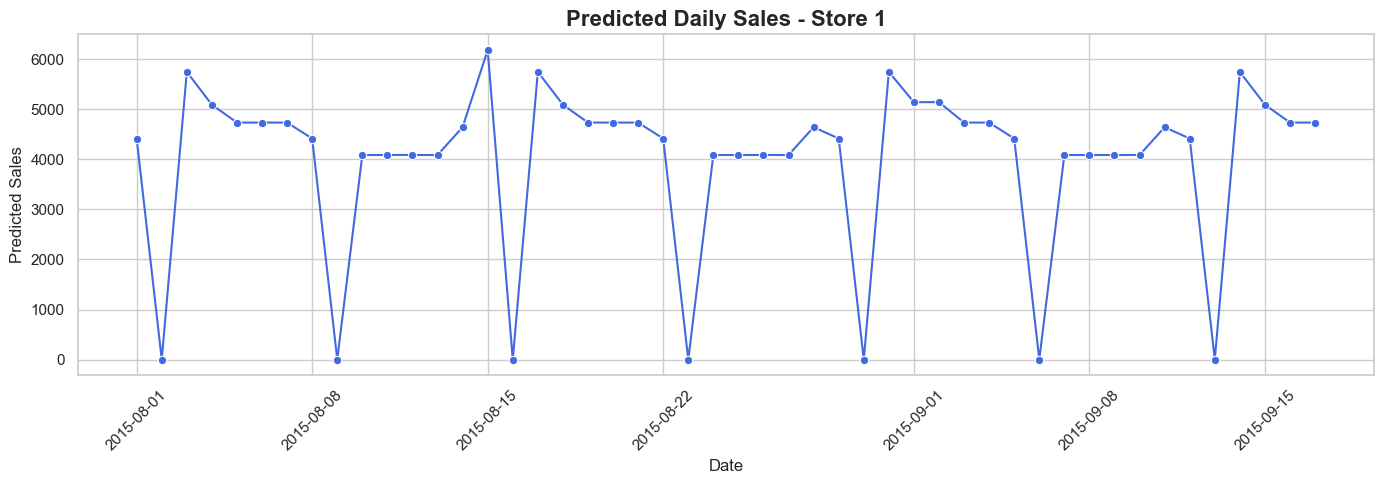

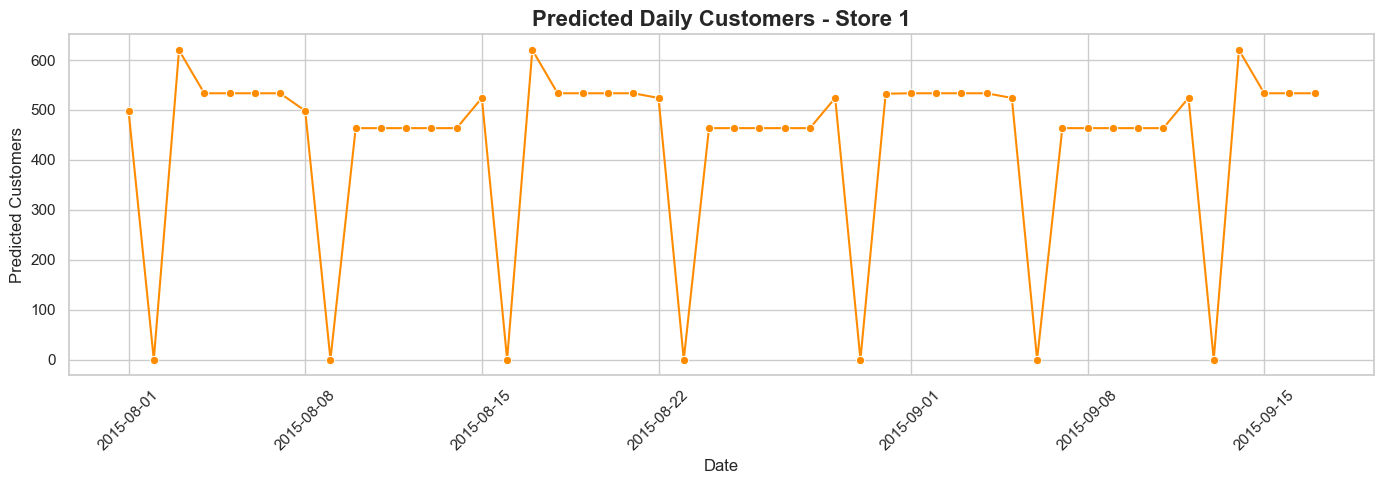

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Sales prediction plot
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=prediction_df,
    x="Date",
    y="Predicted_Sales",
    marker="o",
    color="royalblue"
)

plt.title(
    "Predicted Daily Sales - Store 1",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Customer prediction plot
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=prediction_df,
    x="Date",
    y="Predicted_Customers",
    marker="o",
    color="darkorange"
)

plt.title(
    "Predicted Daily Customers - Store 1",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Predicted Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Create a temporary CSV

In [12]:
import pandas as pd
from pathlib import Path

# Project paths
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

# Load original test dataset
test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    parse_dates=["Date"]
)

# Filter records for Store 1
store_1_df = test_df[test_df["Store"] == 1].copy()

# Sort records by date
store_1_df = store_1_df.sort_values("Date")

# Select the first 42 days
store_1_42_days = store_1_df.head(42).copy()

# Save as a temporary CSV
temp_file = DATA_DIR / "store_1_42_days.csv"

store_1_42_days.to_csv(temp_file, index=False)

print("Temporary CSV created successfully!")
print("File location:", temp_file)
print("Number of records:", len(store_1_42_days))
print("Start Date:", store_1_42_days["Date"].min())
print("End Date:", store_1_42_days["Date"].max())

Temporary CSV created successfully!
File location: C:\Users\ijish\Desktop\Rossmann Sales Forecasting Project\data\store_1_42_days.csv
Number of records: 42
Start Date: 2015-08-01 00:00:00
End Date: 2015-09-11 00:00:00


In [13]:
# Display the first 5 records
display(store_1_42_days.head())

# Check number of records
print("Total records:", len(store_1_42_days))

# Check unique stores
print("Store IDs:", store_1_42_days["Store"].unique())

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
40232,40233,1,6,2015-08-01,1.0,0,0,1
39376,39377,1,7,2015-08-02,0.0,0,0,1
38520,38521,1,1,2015-08-03,1.0,1,0,1
37664,37665,1,2,2015-08-04,1.0,1,0,1
36808,36809,1,3,2015-08-05,1.0,1,0,1


Total records: 42
Store IDs: [1]
